Классификация твитов на сообщающие о реальных катастрофах и ложные (анализ текста, NLP).

### packages installation

### imports

In [1]:
import numpy as np
import pandas as pd
import torch
from torch import nn

import random
import itertools

from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoModelForSequenceClassification, AutoTokenizer, AutoConfig
from transformers import Trainer, TrainingArguments, set_seed
from sentence_transformers import SentenceTransformer

from transformers import DataCollatorWithPadding, EarlyStoppingCallback
from sklearn.metrics import classification_report

import re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

/home/golubev.dmitriy25/venvs/experement_cv_venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(42)

In [3]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option('display.max_colwidth', None)

### EDA

##### первичный анализ атрибутов

In [4]:
# инициализируем датафрейм и смотрим на его размерность + на первые записи
train_df = pd.read_csv('/home/golubev.dmitriy25/itmo_hv/usuf_hw/data_hw_1/train.csv')
display(train_df.shape)
train_df.head()

(7613, 5)

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


In [5]:
# проверим количество уникальных объектов. понадобится длоя дальнейших шагов 
train_df.nunique()

id          7613
keyword      221
location    3341
text        7503
target         2
dtype: int64

In [6]:
# удостоверимся в отсутствующем значимом дисбалансе классов
vc = train_df['target'].value_counts()
pd.DataFrame({'count': vc, 'share': (vc / len(train_df)).round(4)})

,count,share
target,,
0,4342,0.5703
1,3271,0.4297


In [7]:
# посмотрим на количество пропусков в каждом из столбцов
miss = train_df.isna().sum()
pd.DataFrame({'n_missing': miss, 'pct': (miss / len(train_df) * 100).round(2)})

,n_missing,pct
id,0,0.00
keyword,61,0.80
location,2533,33.27
text,0,0.00
target,0,0.00


поскольку в атрибуте location достаточно много пропусков посмотрим, как они сказываются на предсказаниях и примем решение, стоит ли разрабатывать стратегию по заполнению пропусков для этого столбца. и на keywords тоже посмотрим, потому что это единственные признаки с пропусками

In [8]:
for col in ['keyword', 'location']:
    print(f'\nВероятность таргета == 1 в зависимости от пропуска значения в {col}:')
    print(train_df.groupby(train_df[col].isna())['target'].agg(['count', 'mean']).round(3))


Вероятность таргета == 1 в зависимости от пропуска значения в keyword:
         count   mean
keyword              
False     7552  0.428
True        61  0.689

Вероятность таргета == 1 в зависимости от пропуска значения в location:
          count   mean
location              
False      5080  0.432
True       2533  0.424


в результате анализа можно сделать вывод, что пропуск значения в location не несет в себе ничего страшного - что при наличии значения из этого столбца, что при его отсутствии, мы получаем практически идентичный результат по предсказаниям. поэтому нет смысла вводить новый бинарный признак на подобие "is_location_nan". решение касательно использования этого признака примем дальше

а для keywords пока не будет делать преждевременных выводов, мол, пропуск значения там связан с большим количеством положительных классификаций - примеров слишком мало для того, чтобы оправдать такую гипотезу. но будем иметь это ввиду

target              0       1
n_chars count  4342.0  3271.0
        mean     95.7   108.1
        std      35.9    29.3
        min       7.0    14.0
        25%      68.0    88.0
        50%     101.0   115.0
        75%     130.0   136.0
        max     157.0   151.0
n_words count  4342.0  3271.0
        mean     14.7    15.2
        std       6.2     5.1
        min       1.0     2.0
        25%      10.0    11.0
        50%      15.0    15.0
        75%      19.0    19.0
        max      31.0    30.0

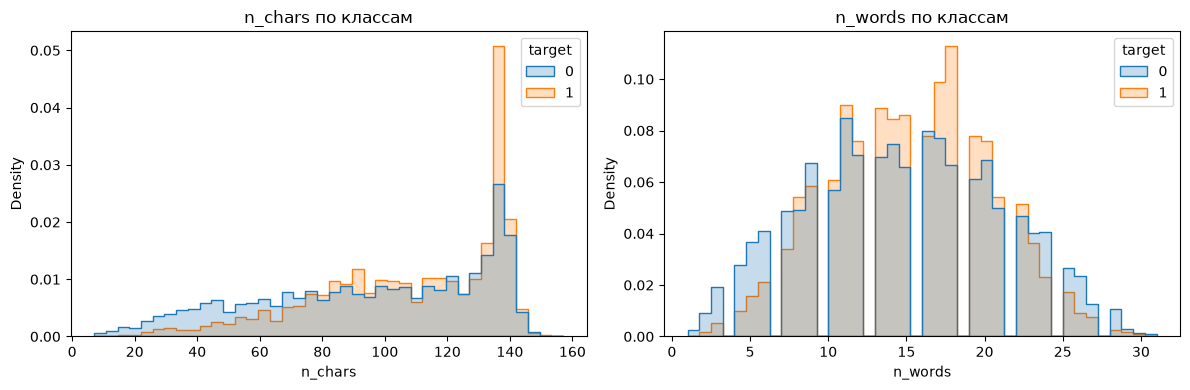

In [9]:
# теперь посмотрим на размерности текстов - влияет ли размер текста на итоговый класс?

train_df['n_chars'] = train_df['text'].str.len()
train_df['n_words'] = train_df['text'].str.split().str.len()
display(train_df.groupby('target')[['n_chars', 'n_words']].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['n_chars', 'n_words']):
    sns.histplot(data=train_df, x=col, hue='target', bins=40, stat='density',
                 common_norm=False, element='step', ax=ax)
    ax.set_title(f'{col} по классам')
    
plt.tight_layout(); plt.show()

исходя из графиков, можем сделать вывод, что твиты класса 1, в среднем, более длинные и реже бывают очень короткими

##### предметный анализ атрибутов keywords и location

при первичной оценке датасета я обнаружил достаточно большое количество грязных записей в столбцах location и keywords. поэтому принял решение провести более подробный анализ этих столбцов

In [10]:
print('уникальных значений в train_df["keyword"]:', train_df['keyword'].nunique())

kw_vals = train_df['keyword'].dropna()
print('значений с кодом "%20" в train_df["keyword"]:', kw_vals[kw_vals.str.contains('%20')].nunique())

уникальных значений в train_df["keyword"]: 221
значений с кодом "%20" в train_df["keyword"]: 36


In [11]:
kw = train_df.groupby('keyword')['target'].agg(['count', 'mean'])
print('значения keywords с долей класса 1, равной нулю или единице:', 
      ((kw['mean'] == 0) | (kw['mean'] == 1)).sum())

kw_share = train_df['keyword'].map(kw['mean'])
print('доля строк, чей keywords имеет долю класса 1 > 0.9 или < 0.1:',
      round(((kw_share > 0.9) | (kw_share < 0.1)).mean(), 3))

значения keywords с долей класса 1, равной нулю или единице: 4
доля строк, чей keywords имеет долю класса 1 > 0.9 или < 0.1: 0.15


In [12]:
has_kw = train_df.dropna(subset=['keyword']).apply(
    lambda r: r['keyword'].replace('%20', ' ').lower() in r['text'].lower(), axis=1)

print('записи, в text которых встречается значение из keywords:', round(has_kw.mean(), 3))

записи, в text которых встречается значение из keywords: 0.887


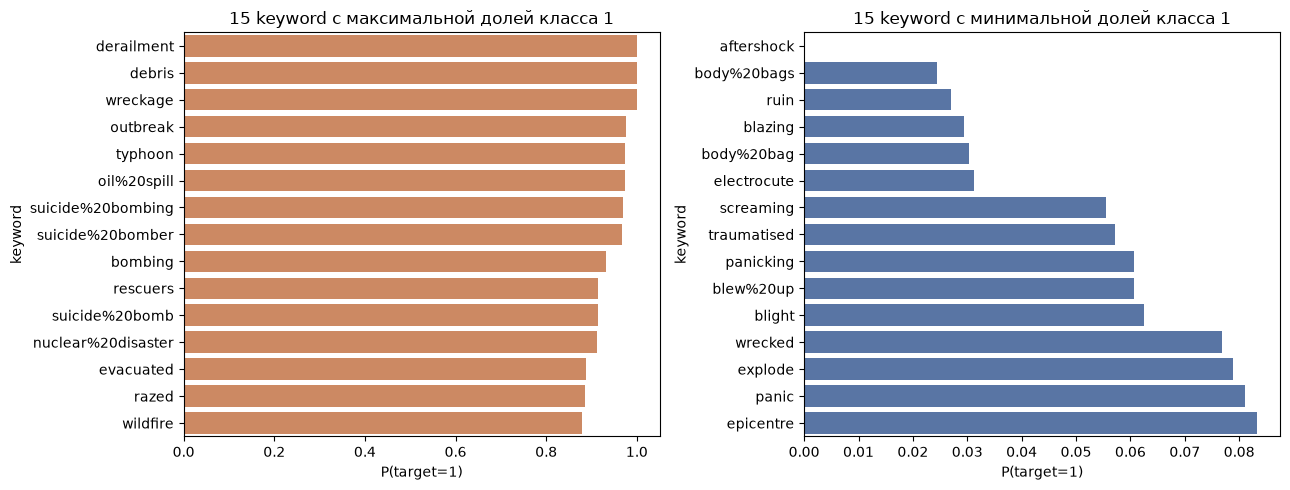

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top = kw.sort_values('mean', ascending=False).head(15)
bot = kw.sort_values('mean').head(15)

sns.barplot(x=top['mean'], y=top.index, ax=axes[0], color='#DD8452')
axes[0].set_title('15 keyword с максимальной долей класса 1'); axes[0].set_xlabel('P(target=1)')
sns.barplot(x=bot['mean'], y=bot.index, ax=axes[1], color='#4C72B0')
axes[1].set_title('15 keyword с минимальной долей класса 1'); axes[1].set_xlabel('P(target=1)')
plt.tight_layout(); plt.show()

ключевые слова с максимальной долей класса 1 - однозначно катастрофные термины, которые редко используют в переносном смысле: `derailment`, `debris`, `wreckage`, `outbreak`, `typhoon`

с минимальной долей класса 1 — слова, которые в твитах чаще встречаются как метафоры или эмоции: `panic`, `screaming`, `blew up`, `ruin`, `explode`. отдельно выделяется `aftershock` (доля 0, поэтому на графике нет столбца). все приведенные примеры двусмысленны - это подтверждает гипотезу, что ключевое слово само по себе не гарантирует класс. нам важен контекст.

In [14]:
# теперь посмотрим на атрибут location

loc = train_df['location'].dropna()
print('уникальных location:', loc.nunique())

display(loc.value_counts().head(15))
print('примеры мусорных значений:', loc[~loc.str.contains(r'[A-Za-z]{3}')].unique()[:15].tolist())

уникальных location: 3341


location
USA                104
New York            71
United States       50
London              45
Canada              29
Nigeria             28
UK                  27
Los Angeles, CA     26
India               24
Mumbai              22
Washington, DC      21
Kenya               20
Worldwide           19
Australia           18
Chicago, IL         18
Name: count, dtype: int64

примеры мусорных значений: ['UK', '304', 'US', '19.600858, -99.047821', '92', '|| c h i c a g o ||', 'L. A.', 'PA', '? ', '\x89ÛÊ\x89ÛÊ\x89ÛÊ', 'ss', 'ph', '??????????????????', 'NC', '302']


отсюда мы видим, что в атрибуте location есть как и мусорные значения, на подобие "?", "\x89ÛÊ\x89ÛÊ\x89ÛÊ" ; значения, которые можно интерпретировать неоднозначно: "PA", "L. A." ; а также дублирующие наименования одной и той же области, но написанные по-разному: "USA" - "United States". при этом некоторые локации являются подклокациями других локаций

In [15]:
# учитывая размер нащего датафрейма (порядка 8тыс. записей), 
# увидев у наиболее популярного значения атрибута location всего 104 вхождения,
# у меня возник вопрос, стоит ли вообще использовать его для дальнейшей классификации

vc = loc.value_counts()
print('заполненных строк:', len(loc))
print('значений, встречающихся один раз:', (vc == 1).sum(), f'({(vc == 1).mean():.1%} уникальных)')
print('доля строк, покрытая топ-15 популярными значениями:', round(vc.head(15).sum() / len(loc), 3))

заполненных строк: 5080
значений, встречающихся один раз: 2818 (84.3% уникальных)
доля строк, покрытая топ-15 популярными значениями: 0.103


отсюда видим, что атрибут location в качестве категориального признака для классификацтора будет бесполезен, поскольку в датасете слишком много уникальных значений, ввиду чего не получится выстроить последовательную связь. использовать этот атрибут можно только в том случае, если мы сможем привести тот или иной его объект к стране

но при этом мы уже знаем, что пропуски в location никак не связаны с таргетом, ввиду чего я принял решение не использовать атрибут location при дальнейшей работе

In [16]:
train_df = train_df.drop(columns=['location'])
train_df.head()

,id,keyword,text,target,n_chars,n_words
0,1,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,69,13
1,4,NaN,Forest fire near La Ronge Sask. Canada,1,38,7
2,5,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,133,22
3,6,NaN,"13,000 people receive #wildfires evacuation orders in California",1,65,8
4,7,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,88,16


##### перейдем к id

при первичном просмотре датасета я заметил, что в id отсутствуют пропущены некоторые значения

пропущенных значений id в диапазоне 1..10873: 3260 (≈ размер test, 3263)


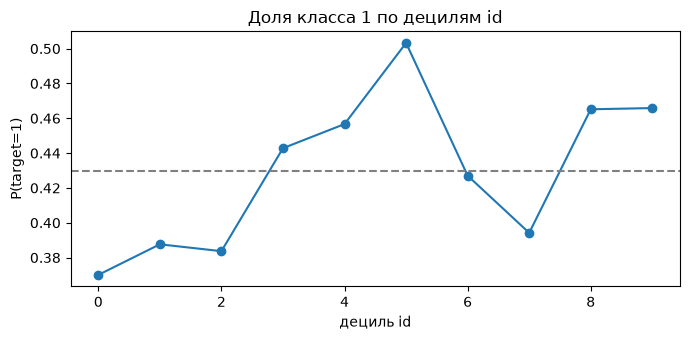

In [17]:
# print('keyword отсортирован по алфавиту в порядке файла:', train_df['keyword'].dropna().is_monotonic_increasing)
# nan_idx = train_df.index[train_df['keyword'].isna()]
# print('строки без keyword: в первых 31 строках —', (nan_idx < 31).sum(),
#       ', в последних 113 —', (nan_idx > 7500).sum())
gaps = train_df['id'].max() - len(train_df)
test_df = pd.read_csv('/home/golubev.dmitriy25/itmo_hv/usuf_hw/data_hw_1/test.csv')
print(f'пропущенных значений id в диапазоне 1..{train_df["id"].max()}: {gaps} (≈ размер test, {len(test_df)})')

train_df['id_decile'] = pd.qcut(train_df['id'], 10, labels=False)
ax = train_df.groupby('id_decile')['target'].mean().plot(marker='o', figsize=(7, 3.5))
ax.axhline(train_df['target'].mean(), ls='--', c='gray')
ax.set_title('Доля класса 1 по децилям id'); ax.set_xlabel('дециль id'); ax.set_ylabel('P(target=1)')
plt.tight_layout(); plt.show()

In [18]:
train_ids, test_ids = set(train_df['id']), set(test_df['id'])
all_ids = train_ids | test_ids
print('объединение train и test покрывает диапазон без пропусков:',
      all_ids == set(range(min(all_ids), max(all_ids) + 1)))

объединение train и test покрывает диапазон без пропусков: True


отсюда мы можем сделать вывод, что train.csv и test.csv изначально были одним файлов. в любом случае, использовать id в предсказаниях не будем

##### нормализация значений в text и в keywords

проведем нормализацию текста, положив результат в атрибут text_norm

In [19]:
import html

def normalize(t):
    t = html.unescape(t).lower()
    t = re.sub(r'http\S+|@\w+|#', ' ', t)
    t = re.sub(r'[^a-z ]', ' ', t)
    return ' '.join(t.split())

train_df['text_norm'] = train_df['text'].map(normalize)

проведем поиск пересечений текстов с разными метками

In [20]:
groups = train_df.groupby('text')['target'].nunique()
conflict = groups[groups > 1].index

for t in list(conflict)[:8]:
    print(train_df.loc[train_df['text'] == t, 'target'].tolist(), '|', t[:110].replace('\n', ' '))

[0, 0, 1] | #Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfi
[1, 1, 0] | #foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #humancons
[1, 1, 0, 1] | .POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc.
[1, 1, 0] | CLEARED:incident with injury:I-495  inner loop Exit 31 - MD 97/Georgia Ave Silver Spring
[1, 0] | Caution: breathing may be hazardous to your health.
[0, 1, 1, 0, 0, 0] | He came to a land which was engulfed in tribal war and turned it into a land of peace i.e. Madinah. #ProphetMu
[0, 1, 0] | Hellfire is surrounded by desires so be careful and donÛªt let your desires control you! #Afterlife
[0, 1] | Hellfire! We donÛªt even want to think about it or mention it so letÛªs not do anything that leads to it #is


и посмотрим на наличие всяеских информационных сущностей в текстах, что были отмечены асессорами как информационные сообщения об угрозах

,доля твитов,P(1 | есть),P(1 | нет)
признак,,,
URL (t.co),0.521,0.547,0.302
@mention,0.264,0.332,0.465
#hashtag,0.229,0.492,0.411
RT,0.014,0.417,0.430
HTML-сущности (&amp; ...),0.047,0.382,0.432
mojibake (\x89Û...),0.088,0.489,0.424
non-ASCII,0.092,0.501,0.422


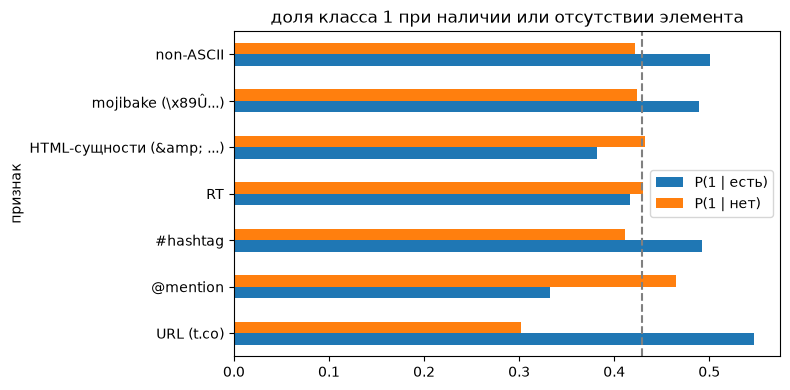

In [21]:
patterns = {
    'URL (t.co)': r't\.co/',
    '@mention': r'@\w+',
    '#hashtag': r'#\w+',
    'RT': r'\bRT\b',
    'HTML-сущности (&amp; ...)': r'&\w+;',
    'mojibake (\\x89Û...)': r'[ÛÒåÊÏÓ]',
    'non-ASCII': r'[^\x00-\x7f]',
}
rows = []
for name, p in patterns.items():
    s = train_df['text'].str.contains(p, regex=True)
    rows.append({'признак': name, 'доля твитов': round(s.mean(), 3),
                 'P(1 | есть)': round(train_df.loc[s, 'target'].mean(), 3),
                 'P(1 | нет)': round(train_df.loc[~s, 'target'].mean(), 3)})
noise = pd.DataFrame(rows).set_index('признак')
display(noise)

ax = noise[['P(1 | есть)', 'P(1 | нет)']].plot.barh(figsize=(8, 4))
ax.axvline(train_df['target'].mean(), ls='--', c='gray')
ax.set_title('доля класса 1 при наличии или отсутствии элемента')
plt.tight_layout(); plt.show()

из приведенного графика становится ясно, что лучше не стоит просто так удалять некоторые информационные сущности из текстов, потому что они имеют достаточно сильную связь с таргетом, и, в принципе, не являются шумом

к ним относятся: URL, упоминания, хэштеги. остальные сущности можно удалять, поскольку они не несут в себе полезной информации. те сущности, что остаются, будут заменены специальными токенами, чтобы не раздувать словарь

In [22]:
MOJIBAKE_MAP = {
    '\x89Û÷': "'", '\x89Ûª': "'",     # одинарные кавычки и апостроф: Can’t
    '\x89ÛÏ': '"', '\x89Û\x9d': '"',  # двойные кавычки: “Airplane”
    '\x89ÛÒ': ' - ', '\x89ÛÓ': ' - ', # тире
    '\x89Û_': '...',                  # многоточие (часто в конце обрезанного твита)
    '\x89ã¢': ' ',                    # маркер списка
    'åÊ': ' ', 'åÈ': ' ', 'å¨': ' ',  # неразрывный пробел и прочие разделители
    'Ì©': 'e', 'Ì_': 'o',             # é (Réunion), ó (Japón)
}
MOJIBAKE_RE = re.compile('|'.join(map(re.escape, sorted(MOJIBAKE_MAP, key=len, reverse=True))))
URL_RE = re.compile(r'https?://\S*|\bhttps?\b|www\.\S+')   # включая обрезанные ссылки
MENTION_RE = re.compile(r'@\w+')
HASHTAG_RE = re.compile(r'#(?=\w)')
RT_RE = re.compile(r'\bRT\b')
NON_ASCII_RE = re.compile(r'[^\x00-\x7f]')


def fix_html(t):
    """Раскодирует HTML-сущности; повторяет, пока текст меняется (бывает &amp;amp;)."""
    prev = None
    while prev != t:
        prev, t = t, html.unescape(t)
    return t


def clean_text(t, url_token='URL', user_token='@USER'):
    t = fix_html(t)                                            # &amp; -> &
    t = MOJIBAKE_RE.sub(lambda m: MOJIBAKE_MAP[m.group()], t)  # чиним кодировку
    t = URL_RE.sub(f' {url_token} ', t)                        # ссылки -> единый токен
    t = MENTION_RE.sub(user_token, t)                          # упоминания -> единый токен
    t = NON_ASCII_RE.sub(' ', t)                               # остатки сломанной кодировки
    t = t.replace('#', ' ')                                    # #wildfire -> wildfire
    t = RT_RE.sub(' ', t)                                      # удаляем RT (в т.ч. из #RT)
    return ' '.join(t.split())                                 # пробелы и \n -> один пробел


def preprocess(df):
    df = df.copy()
    df['has_url'] = df['text'].str.contains(URL_RE).astype(int)
    df['has_mention'] = df['text'].str.contains(MENTION_RE).astype(int)
    df['has_hashtag'] = df['text'].str.contains(HASHTAG_RE).astype(int)

    df['text_clean'] = df['text'].map(clean_text)
    df['keyword'] = df['keyword'].str.replace('%20', ' ', regex=False).fillna('unknown')
    return df


train_df = preprocess(train_df)
test_df = preprocess(test_df)

проверим корректность проведенной очистки

In [23]:
checks = {
    'non-ASCII': r'[^\x00-\x7f]',
    'HTML-сущности': r'&\w+;',
    'http': r'http',
    '#': r'#',
    'RT': r'\bRT\b',
}
for name, p in checks.items():
    print(f'{name:15s} осталось: {train_df["text_clean"].str.contains(p).sum()}')

for i in [31, 52, 7]:
    print('\nдо:   ', train_df.loc[i, 'text'])
    print('после:', train_df.loc[i, 'text_clean'])

non-ASCII       осталось: 0
HTML-сущности   осталось: 0
http            осталось: 0
#               осталось: 0
RT              осталось: 0

до:    @bbcmtd Wholesale Markets ablaze http://t.co/lHYXEOHY6C
после: @USER Wholesale Markets ablaze URL

до:    SANTA CRUZ ÛÓ Head of the St Elizabeth Police Superintendent Lanford Salmon has r ... - http://t.co/vplR5Hka2u http://t.co/SxHW2TNNLf
после: SANTA CRUZ - Head of the St Elizabeth Police Superintendent Lanford Salmon has r ... - URL URL

до:    I'm on top of the hill and I can see a fire in the woods...
после: I'm on top of the hill and I can see a fire in the woods...


теперь, в качестве одного из последних шагов eda, попробуем выловить ошибки разметки из датасета, потому что, как мы видели раньше, конфликты у нас встречаются

In [24]:
kw_mean = train_df.groupby('keyword')['target'].transform('mean')
print('target=1, хотя доля класса 1 у keyword < 0.1:')
display(train_df.loc[(kw_mean < 0.1) & (train_df['target'] == 1), ['keyword', 'text']].head(8))

target=1, хотя доля класса 1 у keyword < 0.1:


,keyword,text
680,blazing,Montgomery come for the blazing hot weather...stay for the STDs. Yet another rejected city slogan.
753,blew up,@BenKin97 @Mili_5499 remember when u were up like 4-0 and blew it in one game? U probs don't because it was before the kings won the cup
775,blew up,Did anyone else see that fireball falling to earth? Look like a plane blew up.
789,blight,@todd_calfee so @mattburgener wanted to see that info on blight u got
808,blight,The #Palestinian #refugee tragedy is a blight on humanity &amp; should shame every #Israeli for living with it. https://t.co/gAAE0nO5du
894,bloody,@TradCatKnight (1) Russia may have played into reason but that link is BS. Okanowa was bloody and mainline invasion looked like a bloody
895,bloody,Bloody insomnia again! Grrrr!! #Insomnia
915,bloody,'I came to kill Indians...for FUN': Video of smirking and remorseless Pakistani killer shows him boasting. http://t.co/FPjLwOXKlg


In [25]:
print('target=0, хотя доля класса 1 у keyword > 0.9:')
display(train_df.loc[(kw_mean > 0.9) & (train_df['target'] == 0), ['keyword', 'text']].head(8))

target=0, хотя доля класса 1 у keyword > 0.9:


,keyword,text
1155,bombing,I think bombing Iran would be kinder... https://t.co/GVm70U2bPm
1157,bombing,Oh and fuck Bill Clinton for bombing us and fuck NATO.
5083,nuclear disaster,Nuclear deal disaster.\n\n#IranDeal #NoNuclearIran #BadIranDeal @JebBush @BarackObama http://t.co/z7phPjtqud
5100,nuclear disaster,@drvox Trump can say nice things about nuclear power but 'drill baby drill!' + AGW denial = policy disaster for nuclear power.
5113,nuclear disaster,Over half of poll respondents worry nuclear disaster fading from public consciousness http://t.co/YtnnnD631z ##fukushima
5267,oil spill,@TroySlaby22 slicker than an oil spill
5303,outbreak,@DrAtomic420 where did you get that pic from where it shows that there is 2 trophies for Outbreak? Or did they photoshop it?
5713,rescuers,I have an unexplainable desire to watch The Rescuers. #childhooddefined


в общем и целом нельзя сказать, что перед нами явные ошибки разметки, от которых стоит избавиться

##### сравним train с test

ранее была вкинута догадка, что трейн и тест получены из одного файла. здесь мы в этом удостоверимся

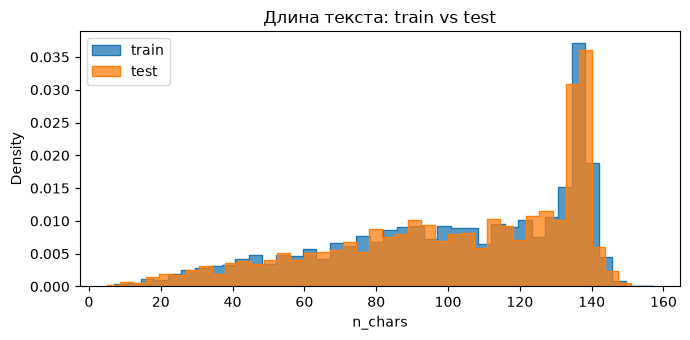

In [27]:
test_df['n_chars'] = test_df['text'].str.len()
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(train_df['n_chars'], bins=40, stat='density', element='step', label='train', ax=ax)
sns.histplot(test_df['n_chars'], bins=40, stat='density', element='step', label='test', ax=ax)
ax.legend(); ax.set_title('Длина текста: train vs test'); plt.tight_layout(); plt.show()

In [28]:
test_df['text_norm'] = test_df['text'].map(normalize)
exact = test_df['text'].isin(set(train_df['text']))
near = test_df['text_norm'].isin(set(train_df['text_norm']))

print(f'твитов test с точной копией в train: {exact.sum()} ({exact.mean():.1%})')
print(f'твитов test с копией после нормализации: {near.sum()} ({near.mean():.1%})')

твитов test с точной копией в train: 78 (2.4%)
твитов test с копией после нормализации: 495 (15.2%)


по итогу получилось, что распределения длин текстов у train_df и test_df и правда совпадают, а пересечения составляют порядка 15% от размера теста. поскольку, в большинстве своем, это не полные пересечения (одинаковые тексты), думаю, стоит их оставить

### models

In [29]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, precision_score, recall_score

In [30]:
SEED = 42
N_SPLITS = 5

In [31]:
def make_folds(df, n_splits=N_SPLITS, seed=SEED):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    groups = df['text_norm'].factorize()[0]

    return list(sgkf.split(df, df['target'], groups))


def best_threshold(y_true, proba, grid=np.arange(0.05, 0.96, 0.01)):
    scores = [f1_score(y_true, (proba >= t).astype(int), zero_division=0) for t in grid]
    
    return float(grid[int(np.argmax(scores))])


def tune_threshold_inner(model_factory, df_tr, n_inner=3, seed=SEED):
    oof = np.zeros(len(df_tr))
    for in_tr, in_va in make_folds(df_tr, n_splits=n_inner, seed=seed):
        m = model_factory()
        m.fit(df_tr.iloc[in_tr])
        oof[in_va] = m.predict_proba(df_tr.iloc[in_va])
    
    return best_threshold(df_tr['target'].values, oof)


def cv_evaluate(model_factory, df, name, folds, tune_threshold=True):
    rows = []
    oof = np.zeros(len(df))
    for k, (tr_idx, va_idx) in enumerate(folds):
        df_tr, df_va = df.iloc[tr_idx], df.iloc[va_idx]
        thr = tune_threshold_inner(model_factory, df_tr) if tune_threshold else 0.5

        model = model_factory()
        model.fit(df_tr)
        proba = model.predict_proba(df_va)
        oof[va_idx] = proba
        pred = (proba >= thr).astype(int)
        y = df_va['target'].values
        rows.append({'model': name, 'fold': k, 'threshold': round(thr, 2),
                     'f1': f1_score(y, pred, zero_division=0),
                     'precision': precision_score(y, pred, zero_division=0),
                     'recall': recall_score(y, pred, zero_division=0)})
    
    return pd.DataFrame(rows), oof

folds = make_folds(train_df)

In [33]:
# проверка фолдов на предмет пересечения значений

for k, (tr, va) in enumerate(folds):
    shared = set(train_df['text_norm'].iloc[tr]) & set(train_df['text_norm'].iloc[va])
    print(f'fold {k}: valid={len(va)}, доля класса 1={train_df["target"].iloc[va].mean():.3f}, '
          f'общих text_norm с train: {len(shared)}')

fold 0: valid=1522, доля класса 1=0.430, общих text_norm с train: 0
fold 1: valid=1523, доля класса 1=0.429, общих text_norm с train: 0
fold 2: valid=1522, доля класса 1=0.430, общих text_norm с train: 0
fold 3: valid=1524, доля класса 1=0.430, общих text_norm с train: 0
fold 4: valid=1522, доля класса 1=0.430, общих text_norm с train: 0


##### baseline

In [34]:
class ConstantBaseline:
    def fit(self, df):
        return self

    def predict_proba(self, df):
        return np.ones(len(df))


class RandomBaseline:
    def __init__(self, seed=SEED):
        self.rng = np.random.default_rng(seed)

    def fit(self, df):
        self.prior = df['target'].mean()
        return self

    def predict_proba(self, df):
        return (self.rng.random(len(df)) < self.prior).astype(float)


class KeywordBaseline:
    def __init__(self, smoothing=10):
        self.m = smoothing

    def fit(self, df):
        self.prior = df['target'].mean()
        stats = df.groupby('keyword')['target'].agg(['sum', 'count'])
        self.enc = (stats['sum'] + self.m * self.prior) / (stats['count'] + self.m)
        return self

    def predict_proba(self, df):
        return df['keyword'].map(self.enc).fillna(self.prior).values

In [35]:
results, oofs = [], {}
for name, factory, tune in [
    ('constant (всегда 1)', ConstantBaseline, False),
    ('random (по доле класса)', RandomBaseline, False),
    ('keyword target encoding', KeywordBaseline, True),
]:
    res, oofs[name] = cv_evaluate(factory, train_df, name, folds, tune_threshold=tune)
    results.append(res)

cv_results = pd.concat(results, ignore_index=True)

In [36]:
cv_results.groupby('model', sort=False)[['f1', 'precision', 'recall']].agg(['mean', 'std']).round(3)

f1        precision        recall       
                          mean    std      mean    std   mean    std
model                                                               
constant (всегда 1)      0.601  0.000     0.430  0.000  1.000  0.000
random (по доле класса)  0.436  0.008     0.437  0.008  0.436  0.008
keyword target encoding  0.690  0.012     0.620  0.016  0.779  0.031

In [37]:
cv_results.pivot(index='fold', columns='model', values='f1').round(3)

model,constant (всегда 1),keyword target encoding,random (по доле класса)
fold,,,
0,0.601,0.674,0.441
1,0.601,0.697,0.441
2,0.601,0.699,0.424
3,0.601,0.699,0.442
4,0.601,0.682,0.433


##### new solution

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

In [40]:
class TfidfLogReg:
    def __init__(self, ngram_range=(1, 2), min_df=2, C=1.0):
        self.pipe = make_pipeline(
            TfidfVectorizer(lowercase=True, ngram_range=ngram_range, min_df=min_df,
                            sublinear_tf=True, strip_accents='unicode'),
            LogisticRegression(C=C, max_iter=1000, random_state=SEED),
        )

    def fit(self, df):
        self.pipe.fit(df['text_clean'], df['target'])
        return self

    def predict_proba(self, df):
        return self.pipe.predict_proba(df['text_clean'])[:, 1]

In [41]:
kw_res, _ = cv_evaluate(KeywordBaseline, train_df, 'keyword target encoding', folds)
tf_res, oof_tfidf = cv_evaluate(TfidfLogReg, train_df, 'tfidf + logreg', folds)

cmp = pd.DataFrame({
    'keyword': kw_res['f1'].values,
    'tfidf + logreg': tf_res['f1'].values,
}, index=pd.Index(range(N_SPLITS), name='fold'))
cmp['разница'] = cmp['tfidf + logreg'] - cmp['keyword']
display(cmp.round(3))
display(cmp.agg(['mean', 'std']).round(3))

wins_all = (cmp['разница'] > 0).all()
diff_gt_spread = cmp['разница'].mean() > cmp[['keyword', 'tfidf + logreg']].std().max()
print('выигрыш на каждом фолде:', wins_all)
print('средняя разница больше разброса между фолдами:', diff_gt_spread)
print('гипотеза подтверждена:', wins_all and diff_gt_spread)

display(tf_res[['fold', 'threshold', 'precision', 'recall', 'f1']].round(3))

,keyword,tfidf + logreg,разница
fold,,,
0,0.674,0.754,0.080
1,0.697,0.752,0.055
2,0.699,0.733,0.035
3,0.699,0.748,0.049
4,0.682,0.759,0.077


,keyword,tfidf + logreg,разница
mean,0.690,0.749,0.059
std,0.012,0.010,0.019


выигрыш на каждом фолде: True
средняя разница больше разброса между фолдами: True
гипотеза подтверждена: True


,fold,threshold,precision,recall,f1
0,0,0.44,0.776,0.732,0.754
1,1,0.42,0.736,0.769,0.752
2,2,0.42,0.707,0.761,0.733
3,3,0.45,0.797,0.705,0.748
4,4,0.45,0.772,0.746,0.759


In [43]:
model = TfidfLogReg().fit(train_df)
vec = model.pipe.named_steps['tfidfvectorizer']
lr = model.pipe.named_steps['logisticregression']

features = np.array(vec.get_feature_names_out())
order = np.argsort(lr.coef_[0])
print('размер словаря:', len(features))
print('\nсильнее всего тянут к классу 1:', list(features[order[-20:]][::-1]))
print('\nсильнее всего тянут к классу 0:', list(features[order[:20]]))

размер словаря: 17681

сильнее всего тянут к классу 1: ['in', 'hiroshima', 'fires', 'california', 'storm', 'fire', 'train', 'wildfire', 'killed', 'bombing', 'suicide', 'near', 'earthquake', 'disaster', 'japan', 'massacre', 'police', 'buildings', 'drought', 'derailment']

сильнее всего тянут к классу 0: ['you', 'my', 'new', 'user', 'love', 'body', 'full', 'your', 'he', 'all', 'me', 'bags', 'let', 'traumatised', 'panic', 'nowplaying', 'blight', 'ruin', 'out', 'screams']


##### using transformers

In [46]:
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import GroupShuffleSplit

In [47]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

# BERTweet обучался на твитах, где ссылки заменены на HTTPURL, а упоминания на @USER
train_df['text_bertweet'] = train_df['text'].map(lambda t: clean_text(t, url_token='HTTPURL'))

device: cpu


In [49]:
def cv_evaluate(model_factory, df, name, folds, tune_threshold=True):
    """Обучает модель на каждом фолде и возвращает метрики по фолдам и OOF-вероятности.

    tune_threshold=True  -> порог подбирается внутренней CV по обучающему фолду;
    tune_threshold=False -> берётся model.threshold, если модель подобрала его сама
                            (как TransformerClassifier), иначе 0.5.
    """
    rows = []
    oof = np.zeros(len(df))
    for k, (tr_idx, va_idx) in enumerate(folds):
        df_tr, df_va = df.iloc[tr_idx], df.iloc[va_idx]

        model = model_factory()
        model.fit(df_tr)
        if tune_threshold:
            thr = tune_threshold_inner(model_factory, df_tr)
        elif hasattr(model, 'threshold'):
            thr = model.threshold
        else:
            thr = 0.5

        proba = model.predict_proba(df_va)
        oof[va_idx] = proba
        pred = (proba >= thr).astype(int)
        y = df_va['target'].values
        rows.append({'model': name, 'fold': k, 'threshold': round(thr, 2),
                     'f1': f1_score(y, pred, zero_division=0),
                     'precision': precision_score(y, pred, zero_division=0),
                     'recall': recall_score(y, pred, zero_division=0)})
    return pd.DataFrame(rows), oof

In [48]:
class TransformerClassifier:
    """Дообучение предобученного трансформера.

    Внутри fit 10% обучающего фолда (с группировкой по text_norm) откладывается
    для выбора лучшей эпохи и порога. Порог сохраняется в self.threshold."""

    def __init__(self, model_name='vinai/bertweet-base', text_col='text_bertweet',
                 max_len=64, batch_size=32, lr=2e-5, epochs=3, warmup=0.1,
                 weight_decay=0.01, holdout=0.1, seed=SEED):
        self.model_name, self.text_col = model_name, text_col
        self.max_len, self.batch_size, self.lr, self.epochs = max_len, batch_size, lr, epochs
        self.warmup, self.weight_decay, self.holdout, self.seed = warmup, weight_decay, holdout, seed

    def _batches(self, texts, labels=None, shuffle=False):
        def collate(b):
            enc = self.tok([texts[i] for i in b], truncation=True, max_length=self.max_len,
                           padding=True, return_tensors='pt')
            if labels is not None:
                enc['labels'] = torch.tensor([labels[i] for i in b])
            return enc
        g = torch.Generator().manual_seed(self.seed)
        return DataLoader(np.arange(len(texts)), batch_size=self.batch_size, shuffle=shuffle,
                          collate_fn=collate, generator=g)

    @torch.no_grad()
    def _proba(self, texts):
        self.model.eval()
        out = []
        for batch in self._batches(texts):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            logits = self.model(**batch).logits
            out.append(torch.softmax(logits, dim=-1)[:, 1].float().cpu().numpy())
        return np.concatenate(out)

    def fit(self, df):
        torch.manual_seed(self.seed)
        np.random.seed(self.seed)
        self.tok = AutoTokenizer.from_pretrained(self.model_name)
        self.model = AutoModelForSequenceClassification.from_pretrained(
            self.model_name, num_labels=2).to(DEVICE)

        # отложенная часть для выбора эпохи и порога (дубликаты не разъезжаются)
        gss = GroupShuffleSplit(n_splits=1, test_size=self.holdout, random_state=self.seed)
        tr_idx, ho_idx = next(gss.split(df, groups=df['text_norm']))
        tr, ho = df.iloc[tr_idx], df.iloc[ho_idx]
        tr_texts, tr_y = tr[self.text_col].tolist(), tr['target'].tolist()
        ho_texts, ho_y = ho[self.text_col].tolist(), ho['target'].values

        loader = self._batches(tr_texts, tr_y, shuffle=True)
        steps = len(loader) * self.epochs
        no_decay = ['bias', 'LayerNorm.weight']
        params = [
            {'params': [p for n, p in self.model.named_parameters() if not any(nd in n for nd in no_decay)],
             'weight_decay': self.weight_decay},
            {'params': [p for n, p in self.model.named_parameters() if any(nd in n for nd in no_decay)],
             'weight_decay': 0.0},
        ]
        opt = torch.optim.AdamW(params, lr=self.lr)
        sched = get_linear_schedule_with_warmup(opt, int(self.warmup * steps), steps)
        use_amp = DEVICE == 'cuda'
        scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

        best_f1, best_state = -1, None
        for epoch in range(self.epochs):
            self.model.train()
            for batch in loader:
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                    loss = self.model(**batch).loss
                opt.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                sched.step()

            p = self._proba(ho_texts)
            thr = best_threshold(ho_y, p)
            f1 = f1_score(ho_y, (p >= thr).astype(int))
            print(f'  epoch {epoch + 1}: holdout f1={f1:.3f} (threshold={thr:.2f})')
            if f1 > best_f1:
                best_f1, self.threshold = f1, thr
                best_state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}

        self.model.load_state_dict(best_state)
        return self

    def predict_proba(self, df):
        return self._proba(df[self.text_col].tolist())

In [ ]:
bt_res, oof_bt = cv_evaluate(TransformerClassifier, train_df, 'bertweet', folds, tune_threshold=False)

all_res = pd.concat([kw_res, tf_res, wc_res, bt_res], ignore_index=True)
display(all_res.groupby('model', sort=False)[['f1', 'precision', 'recall']].agg(['mean', 'std']).round(3))
display(all_res.pivot(index='fold', columns='model', values='f1').round(3))

[transformers] emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 26343.11it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/bertweet-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading fro

### eval

### выводы